<a href="https://colab.research.google.com/github/Phoenix007-sys/Case-Exercise-1/blob/main/Case_Exercise_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Question 1
 Write a function reservoir_temperature(depth_m, surface_temp=4.0, gradient=30.0) that returns temperature in °C. Include docstring, type hints, and input validation.


In [4]:
def reservoir_temperature(
    depth_m: float,
    surface_temp: float = 4.0,
    gradient: float = 30.0,
) -> float:
    """Estimate reservoir temperature from depth using a linear geothermal gradient.

    T = surface_temp + gradient * (depth_m / 1000)

    Args:
        depth_m: Depth below the surface (or seabed) in metres. Must be >= 0.
        surface_temp: Temperature at the surface/seabed in °C. Default 4.0,
            typical of deep seabed water.
        gradient: Geothermal gradient in °C per km. Must be >= 0. Default 30.0.

    Returns:
        Estimated temperature in °C.

    Raises:
        TypeError: If any argument is not a number.
        ValueError: If depth_m or gradient is negative.

    Example:
        >>> reservoir_temperature(3000)
        94.0
    """
    for name, value in (("depth_m", depth_m),
                        ("surface_temp", surface_temp),
                        ("gradient", gradient)):
        if isinstance(value, bool) or not isinstance(value, (int, float)):
            raise TypeError(f"{name} must be a number, got {type(value).__name__}")

    if depth_m < 0:
        raise ValueError("depth_m cannot be negative")
    if gradient < 0:
        raise ValueError("gradient cannot be negative")

    return surface_temp + gradient * (depth_m / 1000)



Question 2
Read a CSV file (well_depths.csv) containing 50 well depth measurements and calculate temperatures for all wells using your function.


well_id,depth_m,temperature_c
W01,1526.0,49.8
W02,1600.0,52.0
W03,1606.1,52.2
W04,1619.2,52.6
W05,1683.3,54.5
W06,1819.2,58.6
W07,1847.8,59.4
W08,1871.0,60.1
W09,1886.9,60.6
W10,1904.0,61.1
W11,2121.9,67.7
W12,2295.4,72.9
W13,2374.6,75.2
W14,2381.8,75.5
W15,2392.8,75.8
W16,2411.6,76.3
W17,2431.2,76.9
W18,2600.1,82.0
W19,2611.9,82.4
W20,2657.6,83.7
W21,2846.4,89.4
W22,2861.0,89.8
W23,2959.3,92.8
W24,3014.1,94.4
W25,3187.7,99.6
W26,3521.4,109.6
W27,3644.9,113.3
W28,3679.8,114.4
W29,3708.2,115.2
W30,3809.4,118.3
W31,3857.1,119.7
W32,3914.9,121.4
W33,3974.1,123.2
W34,4042.7,125.3
W35,4057.7,125.7
W36,4099.5,127.0
W37,4206.8,130.2
W38,4292.6,132.8
W39,4318.3,133.5
W40,4418.9,136.6
W41,4445.9,137.4
W42,4723.3,145.7
W43,4728.5,145.9
W44,4737.7,146.1
W45,4817.6,148.5
W46,4890.0,150.7
W47,4946.8,152.4
W48,5068.7,156.1
W49,5328.9,163.9
W50,5392.5,165.8

Question 3
Create a scatter plot showing temperature vs. depth with a linear trendline. Label axes with units, add a title, and include the trendline equation in the legend.


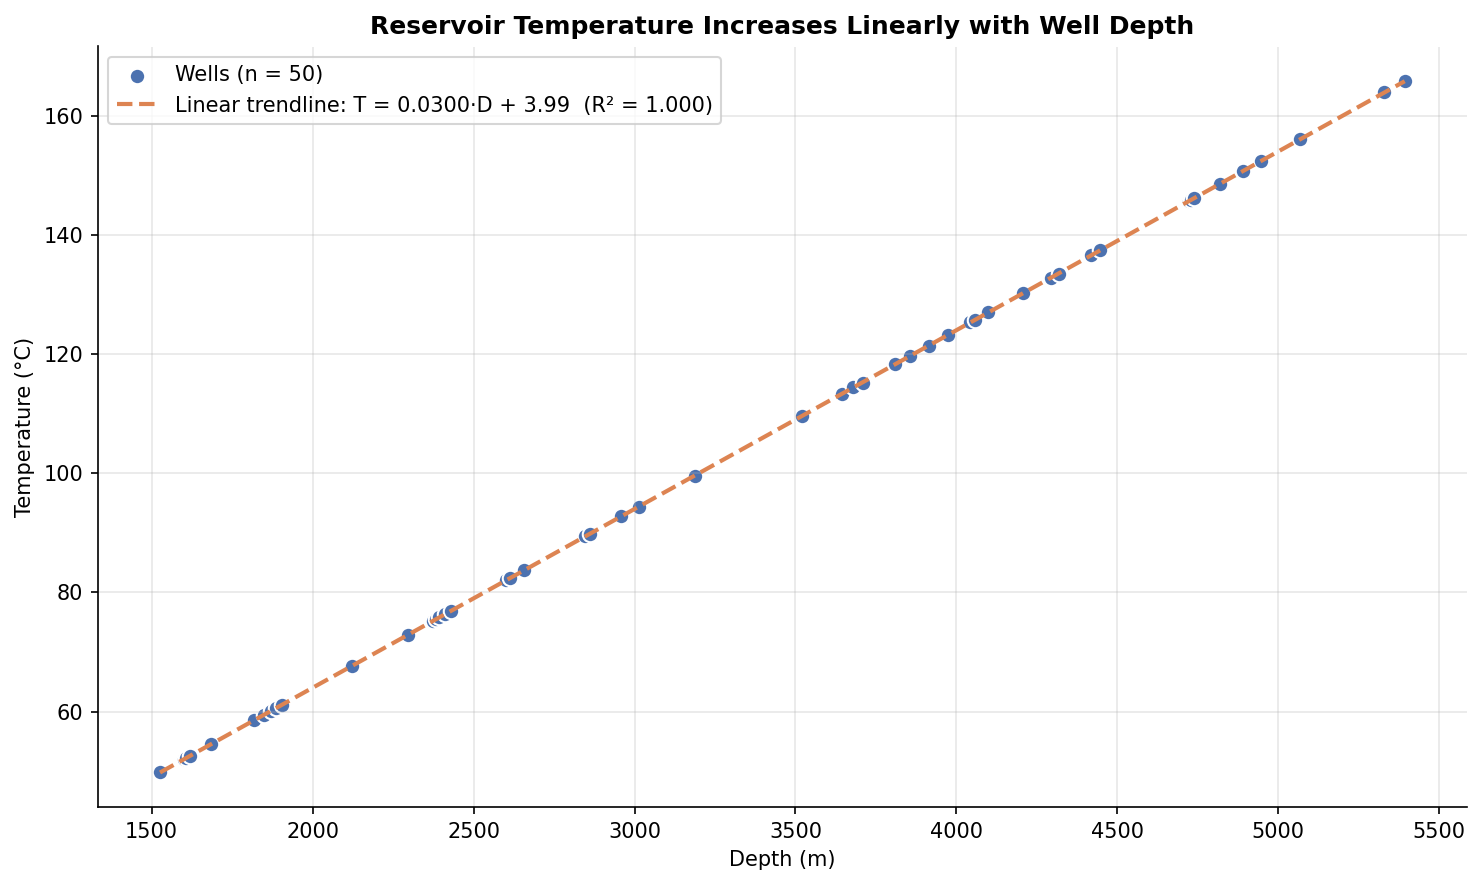

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Create the well_depths.csv file from the provided content
csv_content = """well_id,depth_m,temperature_c
W01,1526.0,49.8
W02,1600.0,52.0
W03,1606.1,52.2
W04,1619.2,52.6
W05,1683.3,54.5
W06,1819.2,58.6
W07,1847.8,59.4
W08,1871.0,60.1
W09,1886.9,60.6
W10,1904.0,61.1
W11,2121.9,67.7
W12,2295.4,72.9
W13,2374.6,75.2
W14,2381.8,75.5
W15,2392.8,75.8
W16,2411.6,76.3
W17,2431.2,76.9
W18,2600.1,82.0
W19,2611.9,82.4
W20,2657.6,83.7
W21,2846.4,89.4
W22,2861.0,89.8
W23,2959.3,92.8
W24,3014.1,94.4
W25,3187.7,99.6
W26,3521.4,109.6
W27,3644.9,113.3
W28,3679.8,114.4
W29,3708.2,115.2
W30,3809.4,118.3
W31,3857.1,119.7
W32,3914.9,121.4
W33,3974.1,123.2
W34,4042.7,125.3
W35,4057.7,125.7
W36,4099.5,127.0
W37,4206.8,130.2
W38,4292.6,132.8
W39,4318.3,133.5
W40,4418.9,136.6
W41,4445.9,137.4
W42,4723.3,145.7
W43,4728.5,145.9
W44,4737.7,146.1
W45,4817.6,148.5
W46,4890.0,150.7
W47,4946.8,152.4
W48,5068.7,156.1
W49,5328.9,163.9
W50,5392.5,165.8
"""
with open("well_depths.csv", "w") as f:
    f.write(csv_content)

# 1. Load the data
df = pd.read_csv("well_depths.csv")
x = df["depth_m"].to_numpy()
y = df["temperature_c"].to_numpy()

# 2. Fit the straight line (degree 1 = linear)
slope, intercept = np.polyfit(x, y, 1)
r2 = np.corrcoef(x, y)[0, 1] ** 2

# 3. Create the figure and axes
fig, ax = plt.subplots(figsize=(10, 6), dpi=150)

# 4. Scatter plot of the wells
ax.scatter(x, y, color="#4C72B0", edgecolor="white", s=55, label="Wells (n = 50)")

# 5. Trendline: evaluate the fitted line at 100 evenly spaced depths
xs = np.linspace(x.min(), x.max(), 100)
ax.plot(
    xs,
    slope * xs + intercept,
    color="#DD8452",
    linestyle="--",
    linewidth=2,
    label=f"Linear trendline: T = {slope:.4f}·D + {intercept:.2f}  (R² = {r2:.3f})",
)

# 6. Titles, labels and styling
ax.set_title("Reservoir Temperature Increases Linearly with Well Depth", fontweight="bold")
ax.set_xlabel("Depth (m)")
ax.set_ylabel("Temperature (°C)")
ax.grid(alpha=0.3)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(loc="upper left", frameon=True)

# 7. Save
plt.tight_layout()
plt.savefig("temperature_vs_depth.png", dpi=150, bbox_inches="tight")

Question 4
Add error handling for negative depths and non-numeric inputs. Write at least 3 test cases that verify correct behaviour for both valid and invalid inputs.

In [2]:
import math


def reservoir_temperature(
    depth_m: float,
    surface_temp: float = 4.0,
    gradient: float = 30.0,
) -> float:
    """Estimate reservoir temperature from depth using a linear geothermal gradient.

    T = surface_temp + gradient * (depth_m / 1000)

    Args:
        depth_m: Depth below the surface (or seabed) in metres. Must be >= 0.
        surface_temp: Temperature at the surface/seabed in °C. Default 4.0.
        gradient: Geothermal gradient in °C per km. Must be >= 0. Default 30.0.

    Returns:
        Estimated temperature in °C.

    Raises:
        TypeError: If any argument is not a real number (e.g. a string, None, bool).
        ValueError: If any argument is NaN or infinite, or if depth_m or
            gradient is negative.

    Example:
        >>> reservoir_temperature(3000)
        94.0
    """
    # Non-numeric check (bool is rejected because True/False would pass as 1/0)
    for name, value in (("depth_m", depth_m),
                        ("surface_temp", surface_temp),
                        ("gradient", gradient)):
        if isinstance(value, bool) or not isinstance(value, (int, float)):
            raise TypeError(f"{name} must be a number, got {type(value).__name__}")
        if not math.isfinite(value):
            raise ValueError(f"{name} must be finite, got {value}")

    # Physical limits
    if depth_m < 0:
        raise ValueError("depth_m cannot be negative")
    if gradient < 0:
        raise ValueError("gradient cannot be negative")

    return surface_temp + gradient * (depth_m / 1000)